# Lab 5 / Assignment 1: Motor parameter identification

**Diyorbek Shokirov, ID 240046** — CSC 413 Robotics

Robot lifted, wheels turn freely; left wheel = M4 / E4, right wheel = M3 / E3. Every robot file line is
`angle_deg,time_ms,pwm`; `battery.txt` has the voltage before and after each run.

| Program | What it does | Files |
|---|---|---|
| `motor_steps.qrs` | 3 s off, then PWM −100 … +100 % in 5 % steps (2 s on, 1 s coasting) | `steps5_M4.txt`, `steps5_M3.txt`, `steps5_M4_repeat.txt` (M4 again) |
| `motor_signal.qrs` | **square wave** ±60 %, 1 s period, 8 s → 1 s off → **chirp** ±60 %, 0.2 → 3 Hz, 8 s → 1 s coasting | `signal_M4.txt`, `signal_M3.txt` |

For M3 only the motor port, the encoder and the file name were changed.

## 1. Motor model

$$\frac{d\omega}{dt} = \frac{U}{T_m k_e} - \frac{\omega}{T_m}, \qquad \frac{d\theta}{dt} = \omega, \qquad
U = \frac{\text{PWM}}{100}\,U_{battery}$$

$U$ [V] motor voltage, $\theta$ [rad] angle, $\omega$ [rad/s] speed, $\omega_{ss} = U/k_e$ the steady speed,
$T_m$ [s] time constant (63 % of $\omega_{ss}$ after $T_m$), $k_e$ [V·s/rad] volts per rad/s.

**Step response.** For constant $U$ from rest, $\omega(t) = \omega_{ss}(1 - e^{-t/T_m})$; integrating once more:

$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right)$$

**Assumptions** (checked below): no inductance, linear friction, constant load, constant battery within a run.

**Code below:** imports, settings, `load()` for a robot file, `segments()` to cut it where the PWM changes,
the battery voltages, and one line
per file to check it (samples, duration, mean time between samples, battery).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

DATA = "motor_data"
MOTORS = {"M4": "left", "M3": "right"}     # motor -> wheel
LINEAR_FROM = 20                           # |PWM| >= 20 %: part of w_ss(PWM) used for the straight-line fits
WINDOW = 3                                 # samples in the moving average of the measured speed


def load(name):                            # one robot file -> angle [deg], time [ms], pwm [%], unchanged
    return np.loadtxt(os.path.join(DATA, name), delimiter=",", unpack=True)


def segments(pwm):                         # -> (start, end) index of every block of equal PWM
    edges = np.r_[0, np.nonzero(np.diff(pwm))[0] + 1, len(pwm)]
    return list(zip(edges[:-1], edges[1:]))


battery = pd.read_csv(os.path.join(DATA, "battery.txt"), index_col="file")   # before_V, after_V of every run
U_bat = battery.mean(axis=1)                                                 # mean voltage of each run
for name in battery.index:
    angle, t, pwm = load(name)
    print(f"{name:22s} {len(t):5d} samples, {(t[-1] - t[0]) / 1000:5.1f} s, dt {np.diff(t).mean():.0f} ms, "
          f"battery {U_bat[name]:.1f} V")

steps5_M4.txt           3608 samples, 123.5 s, dt 34 ms, battery 12.1 V
steps5_M3.txt           3672 samples, 123.6 s, dt 34 ms, battery 12.1 V
steps5_M4_repeat.txt    3802 samples, 123.6 s, dt 33 ms, battery 11.5 V
signal_M4.txt            365 samples,  18.0 s, dt 50 ms, battery 11.5 V
signal_M3.txt            307 samples,  18.0 s, dt 59 ms, battery 11.5 V


## 2. Step responses: $\omega_{ss}$ and $T_m$ at every PWM level

**Code:** `split_steps` cuts a steps file into the 40 steps (time and angle start from 0 at each step, plus the
angle turned in the 1 s coasting); `fit_steps` fits the model to every step with `curve_fit` and keeps
$\omega_{ss}$, $T_m$ and their standard errors (table: every level, both motors, ± = standard error).

**Graph:** 6 of the 40 steps per motor. Dots = measured angle, line of the same colour = fitted model.
Negative PWM turns the wheel backwards, so the angle goes down.

M4                               M3                     
       w_ss, rad/s      ± T_m, s     ±  w_ss, rad/s      ± T_m, s     ± 
PWM, %                                                                  
-100        -15.05  0.005  0.025  0.000      -15.88  0.005  0.033  0.000
-95         -14.59  0.006  0.035  0.000      -15.46  0.006  0.036  0.000
-90         -13.74  0.007  0.052  0.001      -14.79  0.009  0.055  0.001
-85         -12.99  0.007  0.076  0.001      -14.16  0.012  0.073  0.001
-80         -12.68  0.009  0.080  0.001      -13.85  0.011  0.088  0.001
-75         -12.25  0.010  0.084  0.001      -13.48  0.013  0.103  0.001
-70         -11.51  0.010  0.115  0.001      -12.80  0.021  0.095  0.002
-65         -10.64  0.016  0.083  0.002      -12.03  0.024  0.099  0.002
-60         -10.48  0.007  0.150  0.001      -11.88  0.018  0.163  0.002
-55          -9.95  0.008  0.166  0.001      -11.38  0.013  0.199  0.001
-50          -9.56  0.017  0.074  0.002      -11.06  0.012  0.221  0.001
-45          -9.28  0.010  0.178  0.001      -10.53  0.030  0.100  0.003
-40          -8.88  0.015  0.180  0.002      -10.16  0.019  0.216  0.002
-35          -8.39  0.012  0.193  0.002       -9.81  0.015  0.251  0.002
-30          -7.37  0.011  0.225  0.002       -8.77  0.015  0.266  0.002
-25          -6.83  0.005  0.257  0.001       -8.10  0.019  0.287  0.003
-20          -6.14  0.012  0.226  0.002       -7.38  0.019  0.332  0.003
-15          -5.38  0.013  0.268  0.003       -6.48  0.019  0.353  0.004
-10          -4.56  0.006  0.316  0.002       -5.31  0.011  0.370  0.002
-5           -2.51  0.006  0.322  0.003       -2.76  0.012  0.409  0.005
 5            2.27  0.016  0.333  0.008        2.68  0.015  0.367  0.007
 10           4.44  0.016  0.285  0.004        5.59  0.014  0.413  0.003
 15           5.17  0.009  0.238  0.002        6.65  0.014  0.040  0.002
 20           6.10  0.022  0.274  0.004        7.53  0.017  0.304  0.003
 25           6.66  0.019  0.199  0.003        8.35  0.018  0.323  0.003
 30           7.44  0.010  0.215  0.002        8.92  0.017  0.276  0.002
 35           8.52  0.016  0.176  0.002       10.11  0.022  0.231  0.002
 40           9.19  0.011  0.193  0.001       10.53  0.020  0.235  0.002
 45           9.43  0.013  0.185  0.002       11.05  0.016  0.221  0.002
 50           9.88  0.014  0.160  0.002       11.32  0.015  0.207  0.002
 55          10.25  0.013  0.172  0.001       11.77  0.012  0.206  0.001
 60          10.92  0.009  0.150  0.001       12.28  0.014  0.186  0.001
 65          11.09  0.018  0.076  0.002       12.55  0.013  0.168  0.001
 70          12.12  0.011  0.116  0.001       13.42  0.027  0.150  0.003
 75          13.00  0.010  0.100  0.001       13.99  0.012  0.116  0.001
 80          13.45  0.011  0.085  0.001       14.37  0.015  0.094  0.001
 85          13.89  0.011  0.066  0.001       14.72  0.014  0.077  0.001
 90          14.85  0.009  0.059  0.001       15.35  0.009  0.065  0.001
 95          15.85  0.006  0.043  0.000       16.01  0.005  0.044  0.000
 100         16.43  0.004  0.034  0.000       16.46  0.006  0.028  0.000

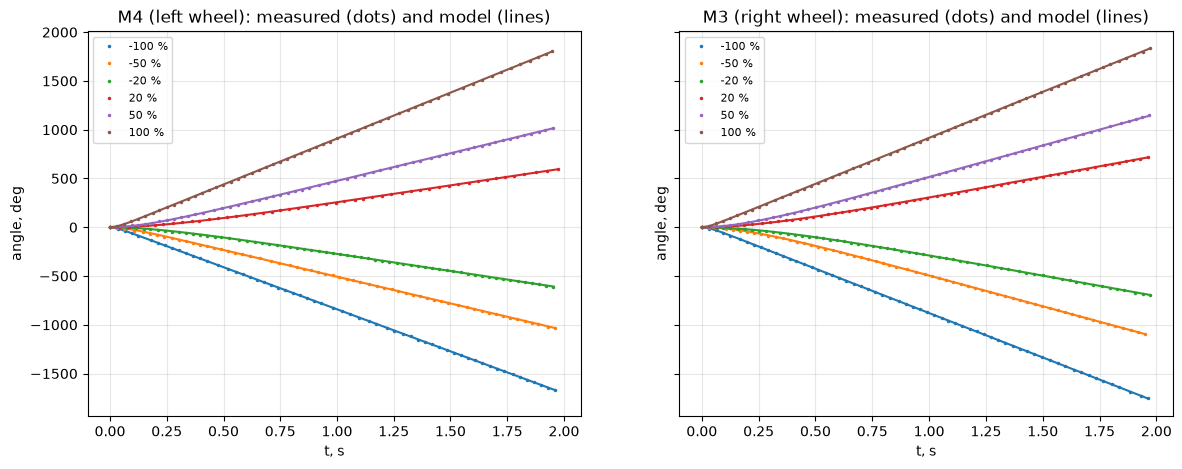

In [2]:
def model(t, w_ss, T_m):                   # theta(t) from section 1
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))


def split_steps(name):                     # -> list of steps: level, t [s], theta [rad], coasting angle [rad]
    angle, t, pwm = load(name)
    seg, steps = segments(pwm), []
    for n, (i, j) in enumerate(seg):
        if pwm[i] != 0:                    # a powered block; the zero block after it is the coasting
            k = seg[n + 1][1] if n + 1 < len(seg) and pwm[j] == 0 else j
            steps.append(dict(level=pwm[i], t=(t[i:j] - t[i]) / 1000, theta=np.radians(angle[i:j] - angle[i]),
                              coast=np.radians(angle[k - 1] - angle[j - 1])))
    return steps


def fit_steps(name):                       # -> table: pwm, w_ss, T_m, their standard errors, coasting angle
    rows = []
    for s in split_steps(name):
        popt, pcov = optimize.curve_fit(model, s["t"], s["theta"], p0=[np.sign(s["level"]) * 8, 0.1],
                                        bounds=([-200, 0.003], [200, 2]))      # T_m between 3 ms and 2 s
        err = np.sqrt(np.diag(pcov))
        rows.append(dict(pwm=s["level"], w_ss=popt[0], w_ss_err=err[0], T_m=popt[1], T_m_err=err[1],
                         coast_deg=np.degrees(s["coast"])))
    return pd.DataFrame(rows)


results = {m: fit_steps(f"steps5_{m}.txt") for m in MOTORS}
display(pd.concat({m: pd.DataFrame({"w_ss, rad/s": r.w_ss.round(2), "±": r.w_ss_err.round(3), "T_m, s": r.T_m.round(3),
                                    "± ": r.T_m_err.round(3)}).set_index(r.pwm.astype(int).rename("PWM, %"))
                   for m, r in results.items()}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, m in zip(axes, MOTORS):
    r = results[m].set_index("pwm")
    for s in split_steps(f"steps5_{m}.txt"):
        if s["level"] in (-100, -50, -20, 20, 50, 100):
            p = ax.plot(s["t"], np.degrees(s["theta"]), ".", ms=3, label=f"{s['level']:.0f} %")
            ax.plot(s["t"], np.degrees(model(s["t"], r.w_ss[s["level"]], r.T_m[s["level"]])), "-", color=p[0].get_color())
    ax.set_title(f"{m} ({MOTORS[m]} wheel): measured (dots) and model (lines)")
    ax.set_xlabel("t, s"); ax.set_ylabel("angle, deg"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

*The model lies on the measured points for every level, since after ~0.3 s the angle is a straight ramp at
$\omega_{ss}$. Differences appear only at the start: the real motor rises faster at first and then creeps to its
final speed (section 6, M4 50 %), so the model is **late** right after the step and slightly **early** after it.*

## 3. Speed from PWM, $k_e$, dead zone and $T_m$

**Code:** for each motor and direction a straight line $\omega_{ss} = s\cdot\text{PWM} + b$ is fitted to the
levels with $|\text{PWM}| \ge 20$ %, then $k_e = U_{battery}/(100\,s)$. Dead zone = largest $|\text{PWM}|$ where
$|\omega_{ss}| < 0.3$ rad/s (none found: the motor turns at ±5 %, so the grey band marks
"smaller than 5 %"). The table is the results table asked for in the assignment.

**Left graph:** steady speed at every PWM level (circles forward, squares backward) and the fitted lines.
**Right graph:** $T_m$ at every level; the legend gives the mean ± spread over $|\text{PWM}| \ge 20$ %.

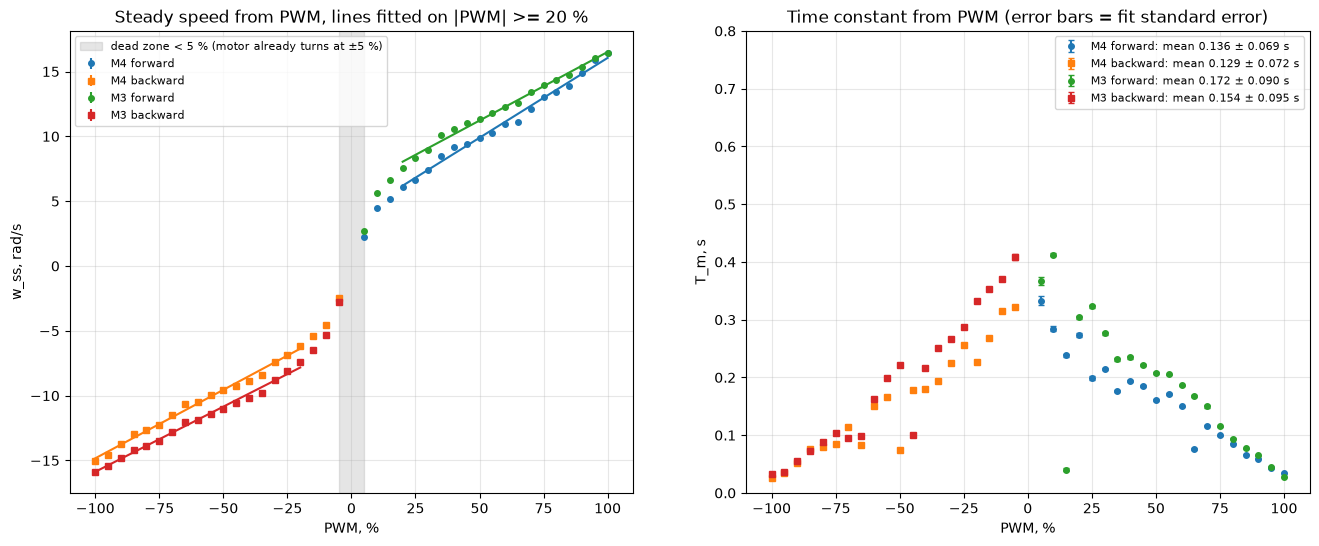


M4 (left wheel)


,Direction,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
0,Forward,< 5,0.1232,0.982,0.136,12.1
1,Backward,< 5,0.1057,1.145,0.129,12.1



M3 (right wheel)


,Direction,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
0,Forward,< 5,0.1058,1.144,0.172,12.1
1,Backward,< 5,0.1005,1.204,0.154,12.1


In [3]:
fits = {}                                  # (motor, +1 forward / -1 backward) -> slope, b, k_e, dead zone, T_m
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for m in MOTORS:
    r = results[m]
    for sign, name in ((1, "forward"), (-1, "backward")):
        d = r[np.sign(r.pwm) == sign]
        lin = d[abs(d.pwm) >= LINEAR_FROM]
        slope, b = np.polyfit(lin.pwm, lin.w_ss, 1)
        dead = abs(d[abs(d.w_ss) < 0.3].pwm).max() if (abs(d.w_ss) < 0.3).any() else 0
        fits[m, sign] = dict(slope=slope, b=b, k_e=U_bat[f"steps5_{m}.txt"] / (100 * abs(slope)), dead=dead,
                             T_m=lin.T_m.mean(), T_m_std=lin.T_m.std())
        p = ax1.errorbar(d.pwm, d.w_ss, yerr=d.w_ss_err, fmt="o" if sign > 0 else "s", ms=4, label=f"{m} {name}")
        x = np.array([sign * LINEAR_FROM, sign * 100])
        ax1.plot(x, slope * x + b, "-", color=p[0].get_color())
        ax2.errorbar(d.pwm, d.T_m, yerr=d.T_m_err, fmt="o" if sign > 0 else "s", ms=4, capsize=2,
                     label=f"{m} {name}: mean {fits[m, sign]['T_m']:.3f} ± {fits[m, sign]['T_m_std']:.3f} s")
ax1.axvspan(-5, 5, color="gray", alpha=0.2, label="dead zone < 5 % (motor already turns at ±5 %)")
ax1.set_title("Steady speed from PWM, lines fitted on |PWM| >= 20 %"); ax1.set_ylabel("w_ss, rad/s")
ax2.set_title("Time constant from PWM (error bars = fit standard error)"); ax2.set_ylabel("T_m, s"); ax2.set_ylim(0, 0.8)
for ax in (ax1, ax2):
    ax.set_xlabel("PWM, %"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

for m in MOTORS:
    print(f"\n{m} ({MOTORS[m]} wheel)")
    display(pd.DataFrame([{"Direction": n, "Dead zone, % PWM": f"{f['dead']:.0f}" if f["dead"] else "< 5",
                           "Slope, rad/s per % PWM": round(abs(f["slope"]), 4), "k_e, V·s/rad": round(f["k_e"], 3),
                           "Mean T_m, s": round(f["T_m"], 3), "U_battery, V": U_bat[f"steps5_{m}.txt"]}
                          for n, f in (("Forward", fits[m, 1]), ("Backward", fits[m, -1]))]))

*Above 20 % the points follow the lines; below 20 % they drop towards zero, but the motor still turns at 5 %
(no dead zone). Forward is faster than backward (M4 +16.6 %, M3 +5.2 %), and M3 is ~15 % faster than M4 at
±50 %. $T_m$ is not constant: 0.3–0.4 s at low PWM because of friction, and ~0.03 s at 100 %, where only one
sample falls inside the transient, so the fit is unreliable.*

## 4. Repeatability

**Code and graph:** `motor_steps.qrs` was run a second time on M4 and fitted the same way; the graph puts the
steady speeds of both runs on top of each other, the title gives the average and largest difference.

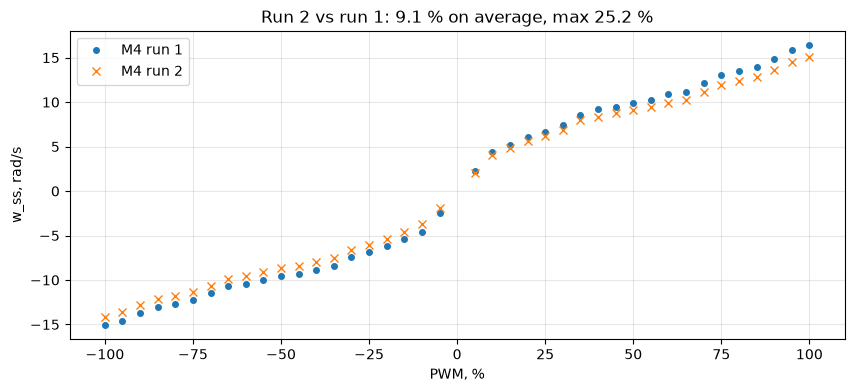

mean T_m 0.132 s and 0.129 s


In [4]:
a, b = results["M4"].set_index("pwm"), fit_steps("steps5_M4_repeat.txt").set_index("pwm")
diff = 100 * (b.w_ss - a.w_ss) / abs(a.w_ss)         # run 2 vs run 1 at every level, %
plt.figure(figsize=(10, 4))
plt.plot(a.index, a.w_ss, "o", ms=4, label="M4 run 1"); plt.plot(b.index, b.w_ss, "x", ms=6, label="M4 run 2")
plt.xlabel("PWM, %"); plt.ylabel("w_ss, rad/s"); plt.grid(alpha=0.3); plt.legend()
plt.title(f"Run 2 vs run 1: {abs(diff).mean():.1f} % on average, max {abs(diff).max():.1f} %")
plt.show()
print(f"mean T_m {a[abs(a.index) >= 20].T_m.mean():.3f} s and {b[abs(b.index) >= 20].T_m.mean():.3f} s")

## 5. Complex signals: model versus real motor

**Code:** each signal file is split at the 1 s pause into the **square wave** and the **chirp**. The motor is
simulated with the recorded PWM (each value held until the next sample, as on the robot) and two models, both
$\dot\omega = (\omega_{target} - \omega)/T_m$:
- **linear**: $\omega_{target} = U/k_e$ ($k_e$, $T_m$ averaged over both directions);
- **measured curve**: $\omega_{target}$ read from the measured $\omega_{ss}(\text{PWM})$ points of section 3,
  straight lines between the 5 % levels, scaled by $U_{signal}/U_{steps}$ because the battery was lower in the
  signal runs (no dead zone above 5 %, so no separate dead-zone model).

The measured speed is `np.gradient` of the angle with a 3-sample moving average.
Fit $= 100\,(1 - \lVert y - \hat y\rVert / \lVert y - \bar y\rVert)$: 100 % = perfect, 0 % = no better than the mean.

**Table:** RMSE and fit % of angle and speed for every motor, signal and model.
**Graphs** (one per signal, M4 left, M3 right): top = angle, middle = speed with the PWM in grey (right axis),
bottom = measured minus model angle.

,motor,signal,model,"angle RMSE, rad","angle fit, %","speed RMSE, rad/s","speed fit, %"
0,M4,square,linear,1.745,-31.1,1.73,71.6
1,M4,square,measured curve,0.404,69.6,1.57,74.3
2,M4,chirp,linear,1.838,-30.6,1.65,59.3
3,M4,chirp,measured curve,1.364,3.1,1.74,56.9
4,M3,square,linear,1.660,-18.3,2.71,57.1
5,M3,square,measured curve,0.339,75.8,1.85,70.6
6,M3,chirp,linear,3.163,-83.2,2.20,48.4
7,M3,chirp,measured curve,1.771,-2.5,1.86,56.2


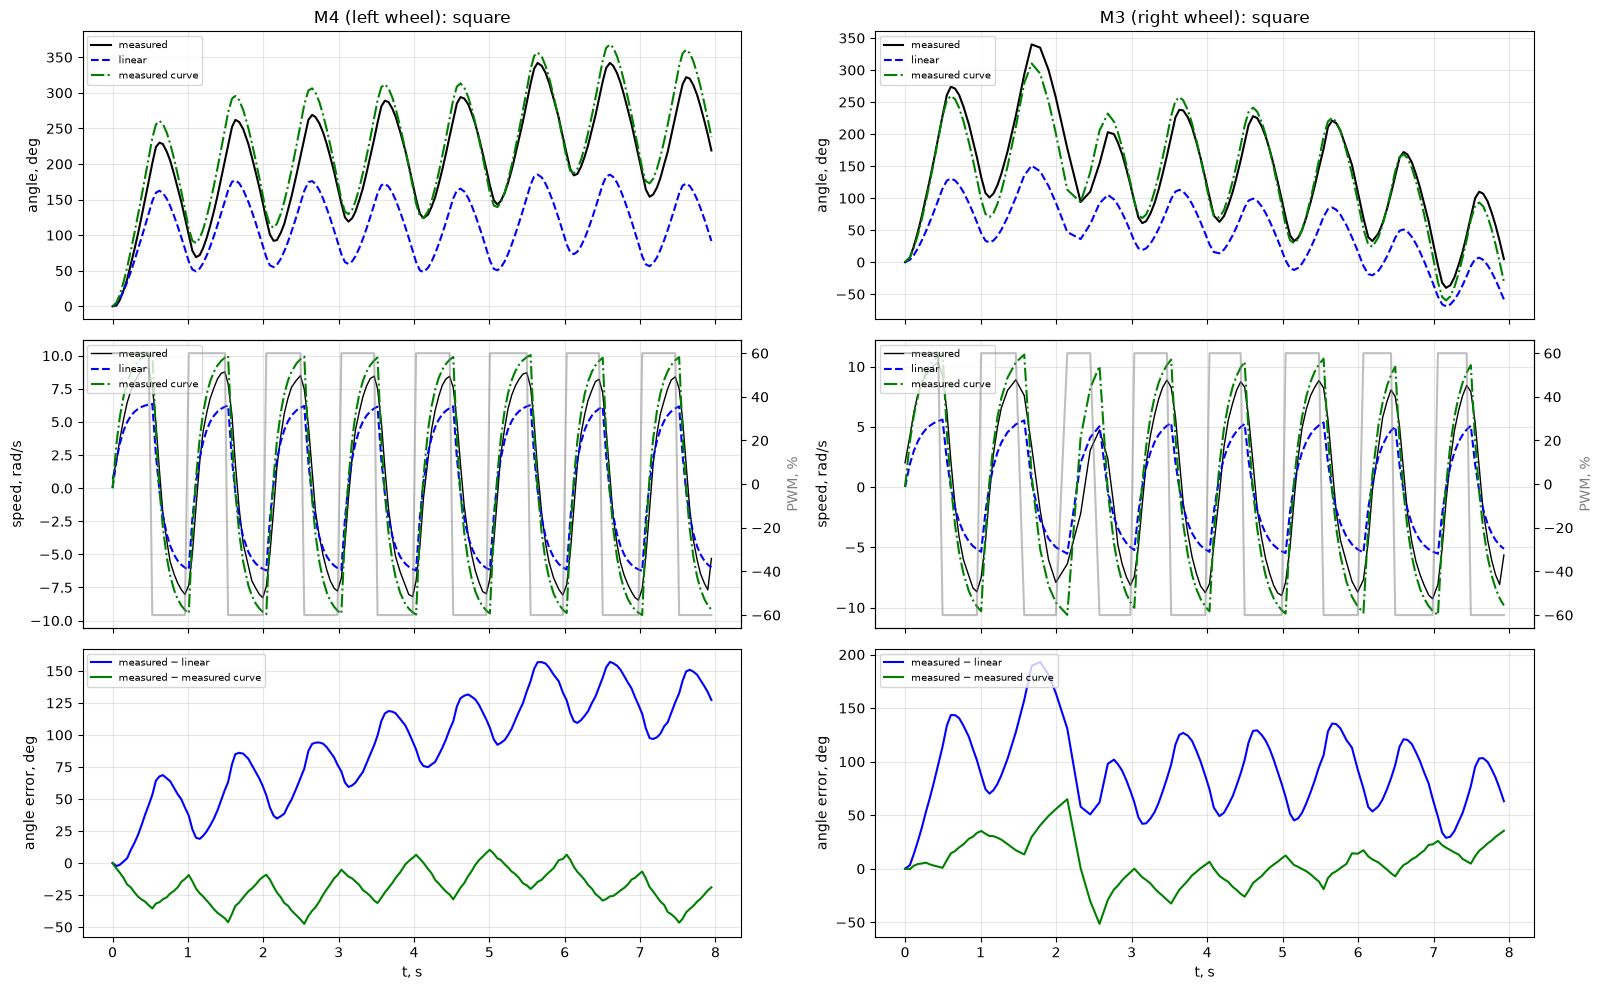

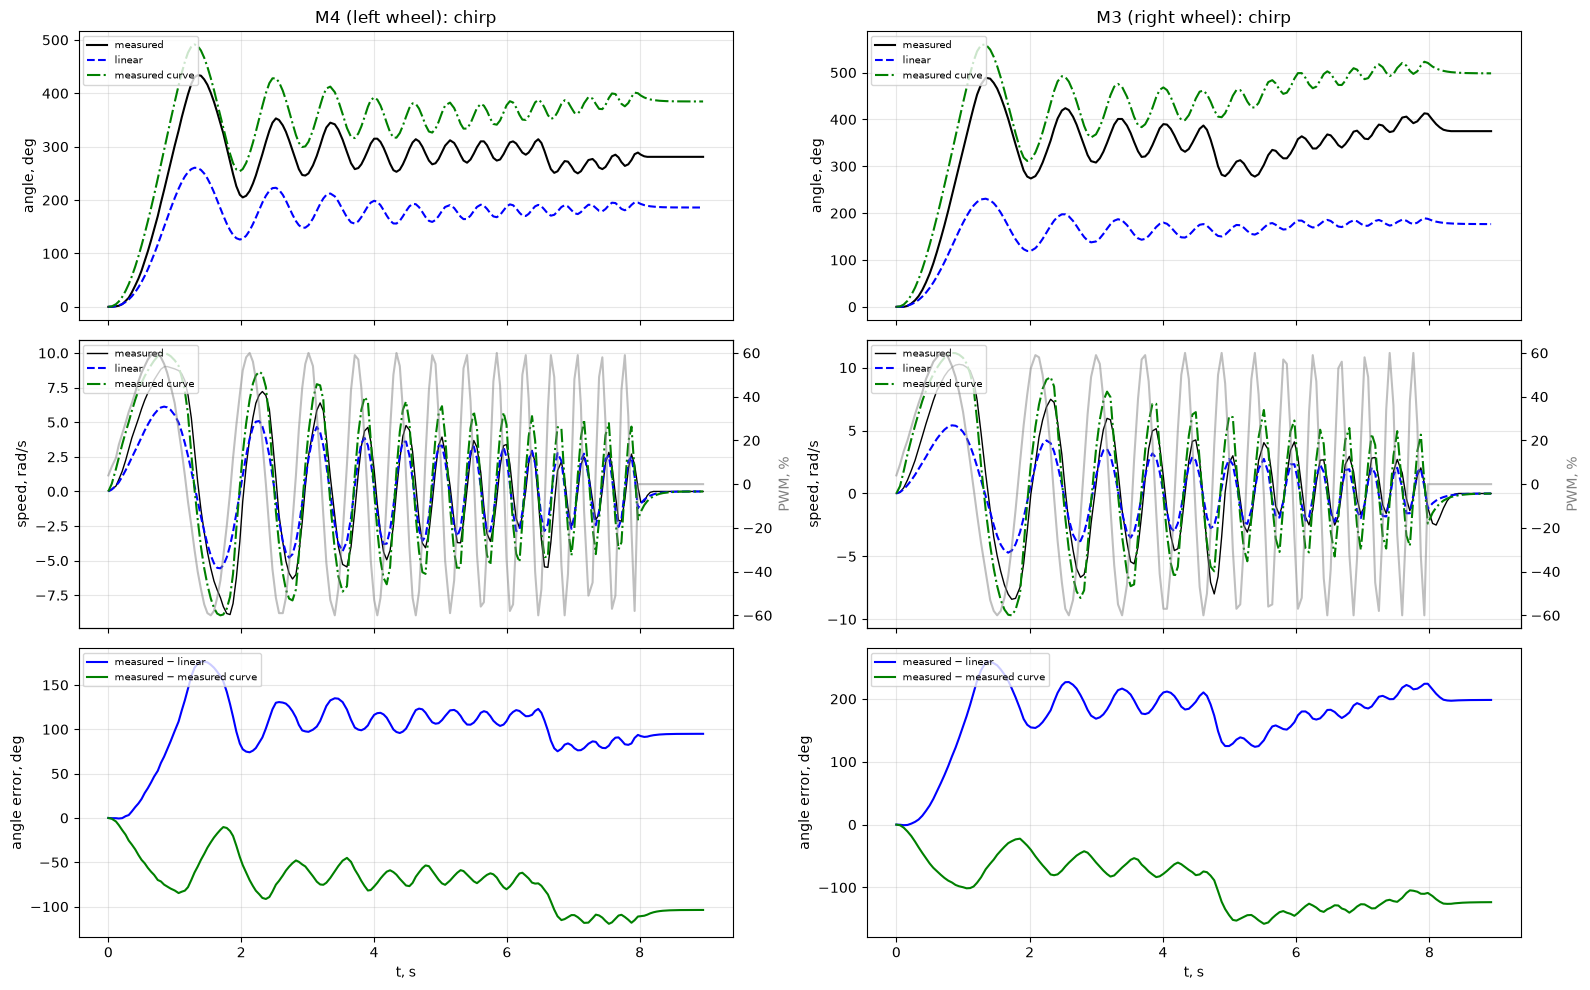

In [5]:
def split_signal(name):                    # -> {"square": (t, theta, pwm), "chirp": (...)}, split at the 1 s pause
    angle, t, pwm = load(name)
    keep = np.r_[True, np.diff(t) > 0]     # two lines with the same ms: keep the first (speed needs dt > 0)
    angle, t, pwm = angle[keep], t[keep], pwm[keep]
    i, j = next((i, j) for i, j in segments(pwm) if pwm[i] == 0 and t[j - 1] - t[i] > 500)   # the 1 s pause
    part = lambda a, b: ((t[a:b] - t[a]) / 1000, np.radians(angle[a:b] - angle[a]), pwm[a:b])
    return {"square": part(0, i), "chirp": part(j, len(t))}


def simulate(t, pwm, U, k_e, T_m, curve=None, U_curve=None):   # -> simulated angle, speed
    def target(tt):                        # steady speed for the PWM at time tt
        p = pwm[max(np.searchsorted(t, tt, side="right") - 1, 0)]   # PWM held until the next sample
        if curve is None:
            return p / 100 * U / k_e                                 # linear model
        return np.interp(p, *curve) * U / U_curve                   # measured curve, scaled to this battery
    y = odeint(lambda st, tt: [(target(tt) - st[0]) / T_m, st[0]], [0, 0], t, hmax=0.01)
    return y[:, 1], y[:, 0]


fit_pct = lambda y, yh: 100 * (1 - np.linalg.norm(y - yh) / np.linalg.norm(y - y.mean()))
rows, sig = [], {}
for m in MOTORS:
    name = f"signal_{m}.txt"
    k_e = (fits[m, 1]["k_e"] + fits[m, -1]["k_e"]) / 2
    T_m = (fits[m, 1]["T_m"] + fits[m, -1]["T_m"]) / 2
    r = results[m]
    order = np.argsort(np.r_[r.pwm, 0])
    curve = (np.r_[r.pwm, 0][order], np.r_[r.w_ss, 0][order])     # measured PWM -> w_ss points, with 0 -> 0
    for kind, (t, theta, pwm) in split_signal(name).items():
        w = np.convolve(np.gradient(theta, t), np.ones(WINDOW) / WINDOW, mode="same")   # measured speed
        models = {"linear": simulate(t, pwm, U_bat[name], k_e, T_m),
                  "measured curve": simulate(t, pwm, U_bat[name], k_e, T_m, curve, U_bat[f"steps5_{m}.txt"])}
        sig[m, kind] = dict(t=t, theta=theta, w=w, pwm=pwm, models=models, k_e=k_e, T_m=T_m)
        for label, (th, ws) in models.items():
            rows.append({"motor": m, "signal": kind, "model": label,
                         "angle RMSE, rad": round(np.sqrt(np.mean((theta - th) ** 2)), 3), "angle fit, %": round(fit_pct(theta, th), 1),
                         "speed RMSE, rad/s": round(np.sqrt(np.mean((w - ws) ** 2)), 2), "speed fit, %": round(fit_pct(w, ws), 1)})
display(pd.DataFrame(rows))

for kind in ("square", "chirp"):
    fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex="col")
    for col, m in enumerate(MOTORS):
        s = sig[m, kind]
        axes[0, col].plot(s["t"], np.degrees(s["theta"]), "k-", lw=1.5, label="measured")
        axes[1, col].plot(s["t"], s["w"], "k-", lw=1, label="measured")
        for (label, (th, ws)), style in zip(s["models"].items(), ("b--", "g-.")):
            axes[0, col].plot(s["t"], np.degrees(th), style, label=label)
            axes[1, col].plot(s["t"], ws, style, label=label)
            axes[2, col].plot(s["t"], np.degrees(s["theta"] - th), style[0] + "-", label=f"measured − {label}")
        axb = axes[1, col].twinx(); axb.plot(s["t"], s["pwm"], color="gray", alpha=0.5); axb.set_ylabel("PWM, %", color="gray")
        axes[0, col].set_title(f"{m} ({MOTORS[m]} wheel): {kind}")
        for row, lab in enumerate(("angle, deg", "speed, rad/s", "angle error, deg")):
            axes[row, col].set_ylabel(lab); axes[row, col].grid(alpha=0.3); axes[row, col].legend(fontsize=7, loc="upper left")
        axes[2, col].set_xlabel("t, s")
    fig.tight_layout()
    plt.show()

**Chirp as a frequency response.** For every period of the chirp (from one upward zero crossing of the PWM to
the next): frequency = 1 / period, gain = speed swing / voltage swing. The first-order model predicts
$1/\left(k_e\sqrt{1 + (2\pi f T_m)^2}\right)$, which halves its slope at the corner frequency $1/(2\pi T_m)$.
**Graph:** dots = measured, lines = model.

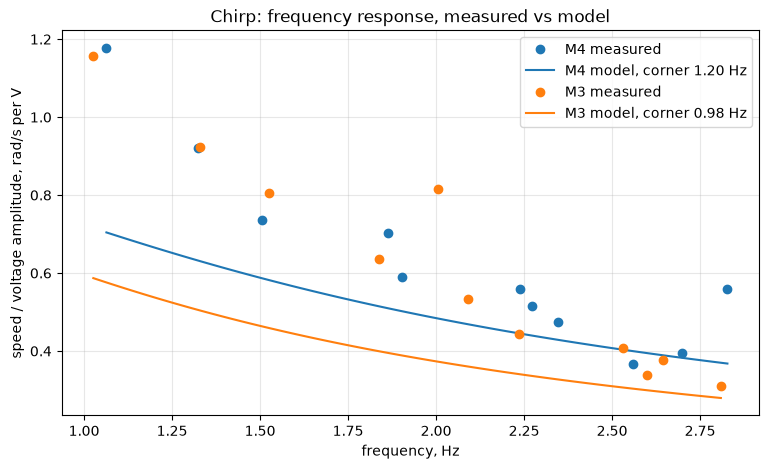

In [6]:
plt.figure(figsize=(9, 5))
for m in MOTORS:
    s = sig[m, "chirp"]
    U = s["pwm"] / 100 * U_bat[f"signal_{m}.txt"]
    zc = np.where(np.diff(np.sign(s["pwm"])) > 0)[0]       # upward zero crossings = one period each
    zc = zc[zc < np.nonzero(s["pwm"])[0][-1]]              # not the power-off at the end
    f, gain = [], []
    for a, b in zip(zc[:-1], zc[1:]):
        if b - a >= 4:                                      # at least 4 samples in the period
            f.append(1 / (s["t"][b] - s["t"][a]))
            gain.append((s["w"][a:b].max() - s["w"][a:b].min()) / (U[a:b].max() - U[a:b].min()))
    p = plt.plot(f, gain, "o", label=f"{m} measured")
    fm = np.linspace(min(f), max(f), 100)
    plt.plot(fm, 1 / (s["k_e"] * np.sqrt(1 + (2 * np.pi * fm * s["T_m"]) ** 2)), "-", color=p[0].get_color(),
             label=f"{m} model, corner {1 / (2 * np.pi * s['T_m']):.2f} Hz")
plt.xlabel("frequency, Hz"); plt.ylabel("speed / voltage amplitude, rad/s per V"); plt.grid(alpha=0.3); plt.legend()
plt.title("Chirp: frequency response, measured vs model")
plt.show()

*The measured-curve model is better: angle fit 69.6 % / 75.8 % on the square wave, against −31 % / −18 % for the
linear model, which ignores the speed offset. The error is largest at reversals and at low speed, where the real
motor is slower than the model. On the chirp, the speed fit (~56 %) is the fairer measure, because the angle fit
(~0 %) is misleading. The chirp also shows that the measured gain falls faster with frequency than the model,
so the real $T_m$ at low speed is larger than the mean 0.13–0.16 s.*

## 6. Artifacts

**First row of graphs:** *zero drift* = encoder angle during the 3 s with the motor off (legend: the first
`time()` value = time offset at the start); *sampling interval* =
histogram of the time between two lines of the step files (the Timer block waits 5 ms); *coasting* = angle the
wheel still turns in the 1 s after power-off, measured vs $\omega_{ss}T_m$ (what the model predicts).

**Table:** forward vs backward (slope and $T_m$), *saturation* = how far the speed at $|\text{PWM}| \ge 80$ %
is from the straight line, battery before/after, mean $k_e$; then M3 vs M4 speed at four levels.

**Last lines:** *differentiation noise* = std of the speed on the steady part of the 50 % step, with and without
the moving average; *backlash* = mean time after a square-wave reversal until the wheel turns the other way,
measured vs model (backlash would make the measured time clearly longer).

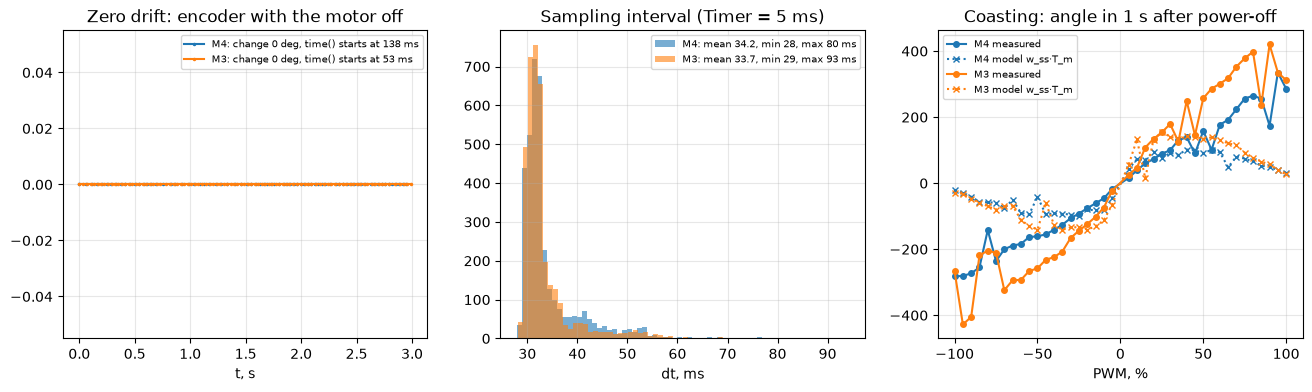

,motor,"slope fwd vs bwd, %","T_m fwd vs bwd, %","w_ss vs line at |PWM| >= 80, %","battery, V","k_e (mean), V·s/rad"
0,M4,16.6,4.8,-2.2 … 2.7,12.1 -> 12.1,1.063
1,M3,5.2,11.9,-1.3 … 1.5,12.1 -> 12.1,1.174


w_ss at -100 %: M4 -15.05, M3 -15.88 rad/s (M3 +5.5 %)
w_ss at  -50 %: M4  -9.56, M3 -11.06 rad/s (M3 +15.7 %)
w_ss at   50 %: M4   9.88, M3  11.32 rad/s (M3 +14.6 %)
w_ss at  100 %: M4  16.43, M3  16.46 rad/s (M3 +0.2 %)
speed noise (std, M4 at 50 %): np.gradient 0.29 rad/s, moving average 0.16 rad/s
M4: speed changes sign 145 ms after a reversal (measured-curve model 97 ms)
M3: speed changes sign 182 ms after a reversal (measured-curve model 127 ms)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for m in MOTORS:
    angle, t, pwm = load(f"steps5_{m}.txt")
    n0 = np.argmax(pwm != 0)                                  # end of the 3 s motor-off block
    axes[0].plot((t[:n0] - t[0]) / 1000, angle[:n0] - angle[0], ".-", ms=3,
                 label=f"{m}: change {angle[:n0].max() - angle[:n0].min():.0f} deg, time() starts at {t[0]:.0f} ms")
    dt = np.diff(t)
    axes[1].hist(dt, bins=np.arange(dt.min() - 0.5, dt.max() + 1.5), alpha=0.6,
                 label=f"{m}: mean {dt.mean():.1f}, min {dt.min():.0f}, max {dt.max():.0f} ms")
    r = results[m]
    p = axes[2].plot(r.pwm, r.coast_deg, "o-", ms=4, label=f"{m} measured")
    axes[2].plot(r.pwm, np.degrees(r.w_ss * r.T_m), "x:", ms=4, color=p[0].get_color(), label=f"{m} model w_ss·T_m")
axes[0].set_title("Zero drift: encoder with the motor off"); axes[1].set_title("Sampling interval (Timer = 5 ms)")
axes[2].set_title("Coasting: angle in 1 s after power-off")
for ax, xl in zip(axes, ("t, s", "dt, ms", "PWM, %")):
    ax.set_xlabel(xl); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.show()

rows = []
for m in MOTORS:
    f, b, r = fits[m, 1], fits[m, -1], results[m]
    hi = r[abs(r.pwm) >= 80]
    line = np.where(hi.pwm > 0, f["slope"] * hi.pwm + f["b"], b["slope"] * hi.pwm + b["b"])
    sat = 100 * (hi.w_ss.values - line) / abs(line)
    before, after = battery.loc[f"steps5_{m}.txt"]
    rows.append({"motor": m, "slope fwd vs bwd, %": round(100 * (abs(f["slope"]) / abs(b["slope"]) - 1), 1),
                 "T_m fwd vs bwd, %": round(100 * (f["T_m"] / b["T_m"] - 1), 1),
                 "w_ss vs line at |PWM| >= 80, %": f"{sat.min():.1f} … {sat.max():.1f}",
                 "battery, V": f"{before} -> {after}", "k_e (mean), V·s/rad": round((f["k_e"] + b["k_e"]) / 2, 3)})
display(pd.DataFrame(rows))
for lvl in (-100, -50, 50, 100):
    a4, a3 = results["M4"].set_index("pwm").w_ss[lvl], results["M3"].set_index("pwm").w_ss[lvl]
    print(f"w_ss at {lvl:4d} %: M4 {a4:6.2f}, M3 {a3:6.2f} rad/s (M3 {100 * (a3 / a4 - 1):+.1f} %)")

s = [q for q in split_steps("steps5_M4.txt") if q["level"] == 50][0]       # differentiation noise: M4, 50 %
w_raw = np.gradient(s["theta"], s["t"]); w_avg = np.convolve(w_raw, np.ones(WINDOW) / WINDOW, mode="same")
steady = (s["t"] > 1) & (s["t"] < s["t"][-1] - 0.1)                       # steady part of the step
print(f"speed noise (std, M4 at 50 %): np.gradient {w_raw[steady].std():.2f} rad/s, moving average {w_avg[steady].std():.2f} rad/s")
for m in MOTORS:                           # backlash: time until the wheel turns the other way after a reversal
    q = sig[m, "square"]
    rev = np.nonzero(np.diff(np.sign(q["pwm"])))[0] + 1                   # first sample after each reversal
    delay = lambda w: 1000 * np.mean([q["t"][r + np.argmax(np.sign(w[r:]) == np.sign(q["pwm"][r]))] - q["t"][r] for r in rev])
    print(f"{m}: speed changes sign {delay(q['w']):.0f} ms after a reversal (measured-curve model {delay(q['models']['measured curve'][1]):.0f} ms)")

*Found: sampling ~34 ms instead of 5 ms (slow loop); coasting 300–400° after power-off (no braking); forward faster
than backward by 5–17 % (friction); M3 ~15 % faster than M4; repeat run ~9 % slower (lower battery); speed noise
0.29 rad/s (1° encoder steps). Not found: zero drift, saturation, sag within a run. Backlash: after a reversal the wheel turns back about 50 ms later than the model (one sample), so a small backlash is possible but can’t be seen clearly at this sampling rate.*

## 7. Analysis

**7.1** Only roughly. The linear model fails (fit −18 … −83 %); the measured-curve model fits the square wave
(70–76 %) better than the chirp (~56 %). The largest errors are at reversals, low speed and high frequency.

**7.2** Not the same: forward is faster by 16.6 % (M4) and 5.2 % (M3). M4 needs two parameter sets; M3 can use one.

**7.3** Slow sampling (~34 ms), coasting (300–400°), asymmetry (5–17 %), M3/M4 spread (~15 %), battery (~9 %),
speed noise (0.29 rad/s). For odometry, the left/right difference and coasting matter most.

**7.4** Reversals are slower than starts from rest, and the motor follows the input only up to ~1 Hz.